# Phase 1: Data Preprocessing & Exploratory Analysis
## Configuration: 3-Tier Clinically Actionable CAD Care Staging
### UCI Cleveland Heart Disease Dataset ($N=303$, 14 Clinical Attributes)

### Clinical Objective:
3-tier clinical care pathways (Tier 0: No CAD [<50%], Tier 1: Mild/Mod CAD [50-74%], Tier 2: Severe/Crit CAD [>=75% multivessel]).

### Strict Zero-Leakage Protocol:
1. **Partition-First Execution**: Stratified 80/20 train/test partition ($N_{\text{train}}=242, N_{\text{test}}=61$) executed **prior** to any data transformation.
2. **Train-Only Imputation**: Median for `ca` (4 missing values) and mode for `thal` (2 missing values) derived exclusively from `X_train`.
3. **Nominal One-Hot Encoding**: Nominal predictors (`cp`, `restecg`, `slope`, `thal`) encoded without imposing false ordinal rankings.
4. **MinMax Feature Scaling**: Scaled continuous clinical variables to $[0, 1]$ learned strictly on `X_train`.
5. **Authentic Distribution**: Zero synthetic samples; natural clinical class frequencies are strictly preserved.

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("[OK] Specialized environment and preprocessing libraries initialized successfully.")

[OK] Specialized environment and preprocessing libraries initialized successfully.


In [2]:
candidates = [
    os.path.join('..', 'datasets', 'heart+disease', 'processed.cleveland.data'),
    os.path.join('datasets', 'heart+disease', 'processed.cleveland.data'),
    'processed.cleveland.data'
]
data_path = next((p for p in candidates if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Could not locate 'processed.cleveland.data'.")

COLUMNS = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

df_raw = pd.read_csv(data_path, names=COLUMNS, na_values='?')
print(f"[OK] Cleveland dataset loaded: {df_raw.shape[0]} patient records, {df_raw.shape[1]} attributes.")

# Formulate 3-Tier Staging Target
def map_to_3tier(val):
    if val == 0:
        return 0
    elif val in [1, 2]:
        return 1
    else:
        return 2

df_raw['target_processed'] = df_raw['target'].apply(map_to_3tier)
class_labels = {0: 'Tier 0: No CAD', 1: 'Tier 1: Mild/Mod CAD', 2: 'Tier 2: Severe/Crit CAD'}

print("\nTarget Class Distribution:")
counts = df_raw['target_processed'].value_counts().sort_index()
for cls, count in counts.items():
    pct = (count / len(df_raw)) * 100
    print(f"  Class {cls} - {class_labels[cls]:22s}: {count:3d} ({pct:.1f}%)")

[OK] Cleveland dataset loaded: 303 patient records, 14 attributes.

Target Class Distribution:
  Class 0 - Tier 0: No CAD        : 164 (54.1%)
  Class 1 - Tier 1: Mild/Mod CAD  :  91 (30.0%)
  Class 2 - Tier 2: Severe/Crit CAD:  48 (15.8%)


### 1. Exploratory Data Analysis & Biomarker Inspection
We examine clinical feature distributions, missing value patterns, and correlations with the target variable.

Missing Clinical Observations:
  Feature 'ca': 4 missing values (1.32%)
  Feature 'thal': 2 missing values (0.66%)


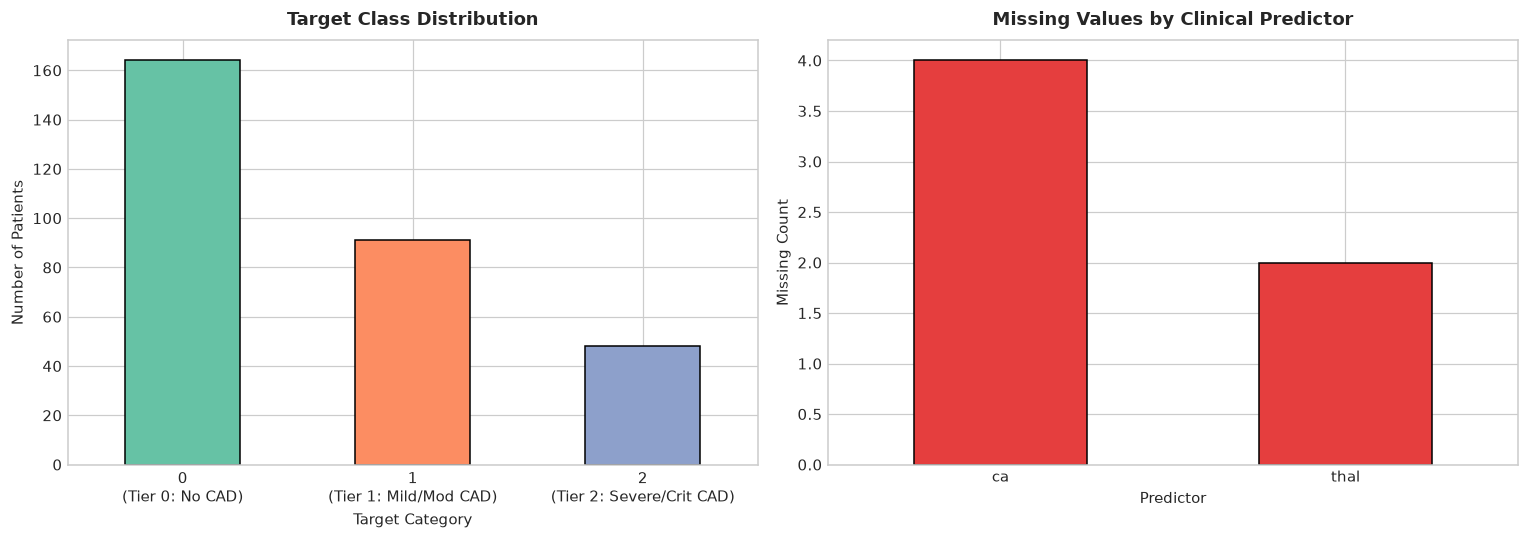

In [3]:
# Missing value assessment
missing_counts = df_raw.drop(columns=['target_processed']).isna().sum()
missing_features = missing_counts[missing_counts > 0]

print("Missing Clinical Observations:")
for feat, count in missing_features.items():
    print(f"  Feature '{feat}': {count} missing values ({count/len(df_raw)*100:.2f}%)")

# Target Distribution Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target Bar Plot
counts.plot(kind='bar', color=sns.color_palette('Set2', len(counts)), ax=axes[0], edgecolor='black')
axes[0].set_title('Target Class Distribution', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Target Category', fontsize=10)
axes[0].set_ylabel('Number of Patients', fontsize=10)
axes[0].set_xticklabels([f"{c}\n({class_labels[c]})" for c in counts.index], rotation=0)

# Missing Values Plot
if len(missing_features) > 0:
    missing_features.plot(kind='bar', color='#e53e3e', ax=axes[1], edgecolor='black')
    axes[1].set_title('Missing Values by Clinical Predictor', fontsize=12, fontweight='bold', pad=10)
    axes[1].set_xlabel('Predictor', fontsize=10)
    axes[1].set_ylabel('Missing Count', fontsize=10)
    axes[1].set_xticklabels(missing_features.index, rotation=0)
else:
    axes[1].text(0.5, 0.5, 'No Missing Values Detected', horizontalalignment='center', verticalalignment='center')

plt.tight_layout()
plt.show()

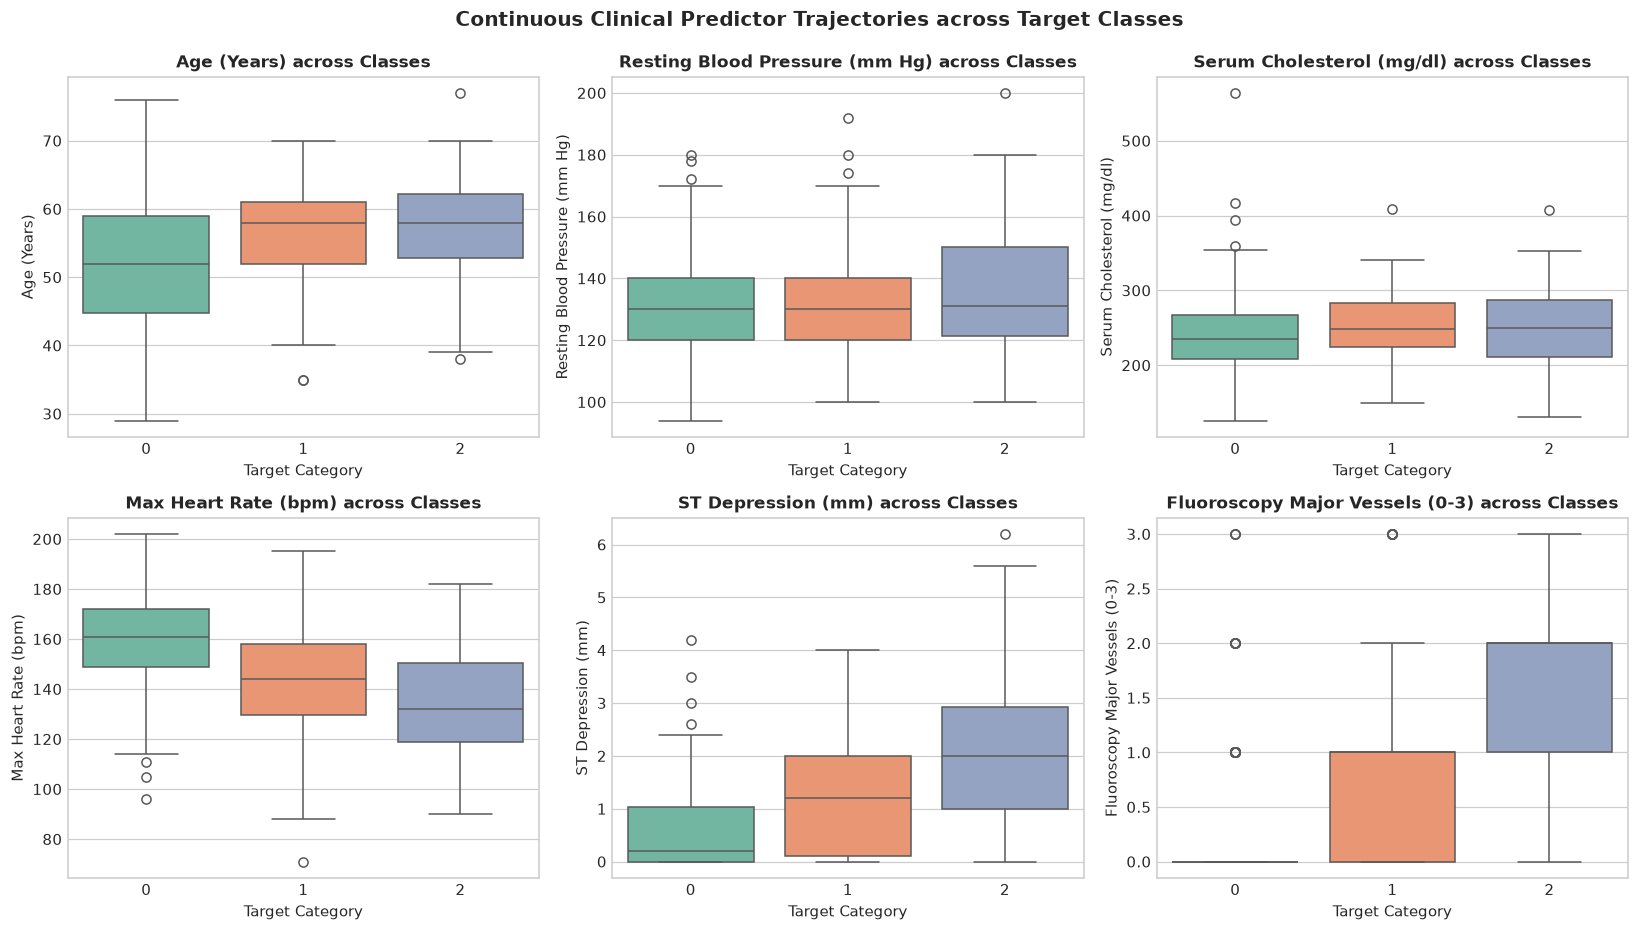

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
continuous_cols = [
    ('age', 'Age (Years)'),
    ('trestbps', 'Resting Blood Pressure (mm Hg)'),
    ('chol', 'Serum Cholesterol (mg/dl)'),
    ('thalach', 'Max Heart Rate (bpm)'),
    ('oldpeak', 'ST Depression (mm)'),
    ('ca', 'Fluoroscopy Major Vessels (0-3)')
]

for idx, (col, lbl) in enumerate(continuous_cols):
    ax = axes[idx // 3, idx % 3]
    sns.boxplot(x='target_processed', y=col, data=df_raw, palette='Set2', ax=ax)
    ax.set_title(f'{lbl} across Classes', fontsize=11, fontweight='bold')
    ax.set_xlabel('Target Category')
    ax.set_ylabel(lbl)

plt.suptitle('Continuous Clinical Predictor Trajectories across Target Classes', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

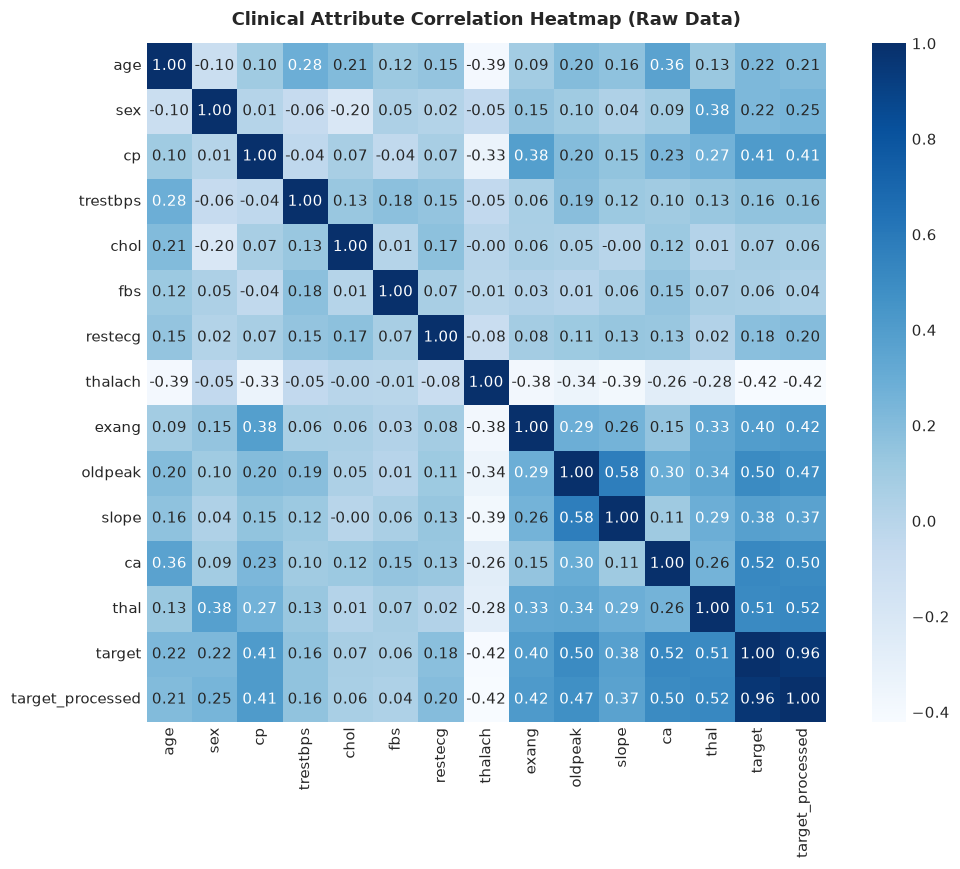

In [5]:
plt.figure(figsize=(10, 8))
numeric_df = df_raw.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', cbar=True, square=True)
plt.title('Clinical Attribute Correlation Heatmap (Raw Data)', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### 2. Zero-Leakage Preprocessing Execution
We perform the stratified 80/20 train/test split. All missing value imputations, dummy encodings, and MinMax scaling boundaries are learned strictly from `X_train`.

In [6]:
# 1. Feature-Target Separation & Stratified Split
X = df_raw.drop(columns=['target', 'target_processed']).copy()
y = df_raw['target_processed'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"[OK] Train split: {X_train.shape[0]} patients | Test split: {X_test.shape[0]} patients")

# 2. Imputation fit strictly on X_train
ca_median = X_train['ca'].median()
thal_mode = X_train['thal'].mode()[0]

X_train['ca'] = X_train['ca'].fillna(ca_median)
X_test['ca'] = X_test['ca'].fillna(ca_median)
X_train['thal'] = X_train['thal'].fillna(thal_mode)
X_test['thal'] = X_test['thal'].fillna(thal_mode)

print(f"[OK] Imputed 'ca' using training median ({ca_median}) and 'thal' using training mode ({thal_mode}).")

# 3. One-Hot Encoding for nominal attributes (cp, restecg, slope, thal)
nominal_cols = ['cp', 'restecg', 'slope', 'thal']
X_train_ohe = pd.get_dummies(X_train, columns=nominal_cols, drop_first=False)
X_test_ohe = pd.get_dummies(X_test, columns=nominal_cols, drop_first=False)

# Guarantee identical feature space between train and test
X_train_ohe, X_test_ohe = X_train_ohe.align(X_test_ohe, join='left', axis=1, fill_value=0)
print(f"[OK] Nominal predictors expanded to {X_train_ohe.shape[1]} one-hot columns.")

# 4. MinMax Scaling on continuous attributes
cont_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
scaler = MinMaxScaler()
X_train_scaled = X_train_ohe.copy()
X_test_scaled = X_test_ohe.copy()

X_train_scaled[cont_cols] = scaler.fit_transform(X_train_ohe[cont_cols])
X_test_scaled[cont_cols] = scaler.transform(X_test_ohe[cont_cols])

X_train_res, y_train_res = X_train_scaled, y_train
print(f"[OK] Training split preserved authentically: {len(y_train)} instances (Zero SMOTE).")

[OK] Train split: 242 patients | Test split: 61 patients
[OK] Imputed 'ca' using training median (0.0) and 'thal' using training mode (3.0).
[OK] Nominal predictors expanded to 22 one-hot columns.
[OK] Training split preserved authentically: 242 instances (Zero SMOTE).


### 3. Before-and-After Preprocessing Verification
We verify that scaling successfully mapped continuous features to $[0, 1]$ and that no NaN values or column mismatches remain.

=== PREPROCESSING VERIFICATION AUDIT ===
X_train shape: (242, 22) | X_test shape: (61, 22)
y_train shape: (242,) | y_test shape: (61,)
NaN values in X_train: 0
NaN values in X_test : 0
Feature columns match exactly: True


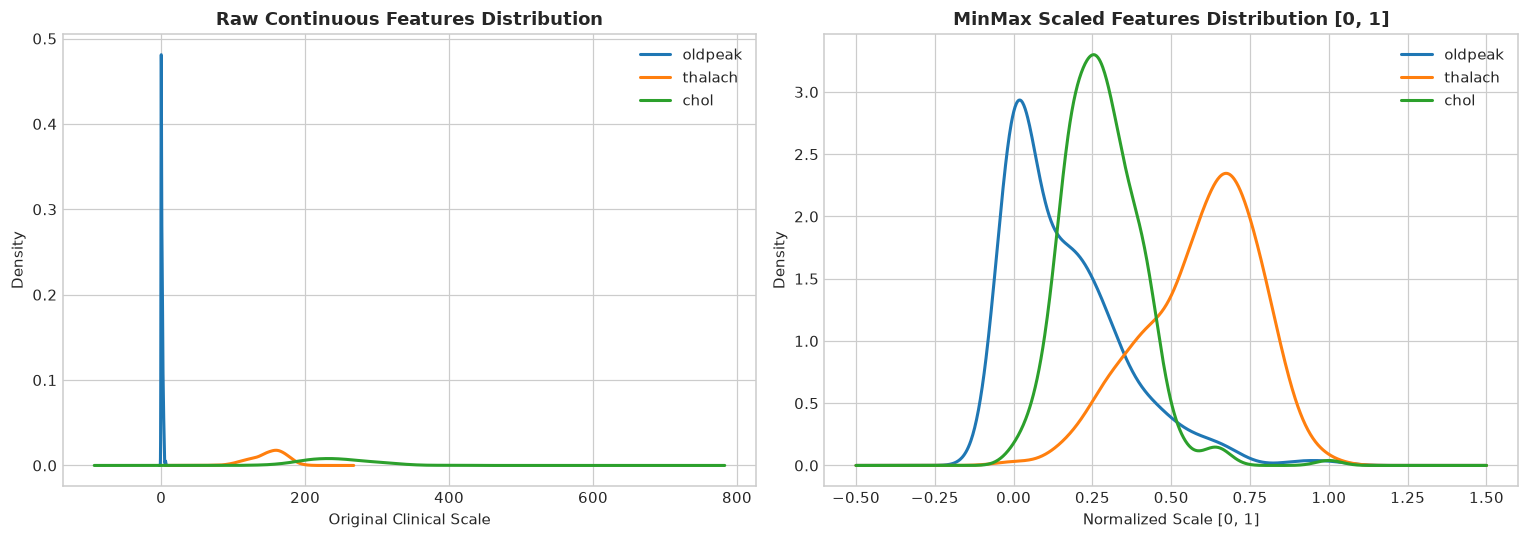

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw distribution of oldpeak and thalach
df_raw[['oldpeak', 'thalach', 'chol']].plot(kind='density', ax=axes[0], lw=2)
axes[0].set_title('Raw Continuous Features Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Original Clinical Scale')

# Scaled distribution
X_train_scaled[['oldpeak', 'thalach', 'chol']].plot(kind='density', ax=axes[1], lw=2)
axes[1].set_title('MinMax Scaled Features Distribution [0, 1]', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Normalized Scale [0, 1]')

plt.tight_layout()
plt.show()

# Verification summary table
print("=== PREPROCESSING VERIFICATION AUDIT ===")
print(f"X_train shape: {X_train_res.shape} | X_test shape: {X_test_scaled.shape}")
print(f"y_train shape: {y_train_res.shape} | y_test shape: {y_test.shape}")
print(f"NaN values in X_train: {pd.DataFrame(X_train_res).isna().sum().sum()}")
print(f"NaN values in X_test : {pd.DataFrame(X_test_scaled).isna().sum().sum()}")
print(f"Feature columns match exactly: {(X_train_scaled.columns == X_test_scaled.columns).all()}")

### 4. Summary & Transition to Baseline Modeling
The dataset has been completely processed under a strict **Zero-Leakage Protocol**.
- Feature matrix contains 22 preprocessed predictor columns.
- Holdout test set ($N=61$) is completely pristine and ready for baseline evaluation (`baseline.ipynb`) and hyperparameter tuning (`hyperparameter_tuning.ipynb`).